In [ ]:
import pandas as pd

# Original dataset: download from UCI and place it next to this notebook (see README)
filename = "diabetic_data.csv"

# Preserve literal categories such as "None" and "?"
# Treat empty CSV fields as actual missing values
df = pd.read_csv(
    filename,
    keep_default_na=False,
    na_values=[""],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
    },
)

# Verify the expected original dataset
assert df.shape == (101766, 50), (
    f"Expected the original dataset with shape (101766, 50), got {df.shape}."
)

assert df["readmitted"].notna().all()
assert set(df["readmitted"].unique()) == {"<30", ">30", "NO"}

print("Loaded file:", filename)
print("Original dataset shape:", df.shape)

print("\nTarget counts:")
print(df["readmitted"].value_counts(dropna=False))

print("\nLiteral 'None' counts in laboratory columns:")
print(df[["A1Cresult", "max_glu_serum"]].eq("None").sum())

Loaded file: diabetic_data.csv
Original dataset shape: (101766, 50)

Target counts:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Literal 'None' counts in laboratory columns:
A1Cresult        84748
max_glu_serum    96420
dtype: int64


In [ ]:
df_clean = df.copy()

In [ ]:

# عرض عدد الصفوف والأعمدة
print("Shape:", df_clean.shape)

# فحص القيم الحالية في عمود الهدف
print("\nTarget values:")
print(df_clean["readmitted"].value_counts(dropna=False))

Shape: (101766, 50)

Target values:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


In [ ]:
# تحويل الهدف إلى 0 و1
df_clean["readmitted"] = df_clean["readmitted"].map({
    "<30": 1,
    ">30": 0,
    "NO": 0
})

# التحقق من النتيجة، بما فيها أي قيم لم يشملها التحويل
print(df_clean["readmitted"].value_counts(dropna=False))

readmitted
0    90409
1    11357
Name: count, dtype: int64


### Defining the Model Cohort

We excluded 2,423 encounters with discharge disposition codes `[11, 13, 14, 19, 20, 21]`, representing death or hospice discharge.

Patients who died cannot subsequently be readmitted. Hospice encounters were excluded from the baseline model because their care goals and readmission decisions differ from those of the target population; readmission is not necessarily impossible for these patients.

This is a cohort-selection decision, not the removal of incorrect records. Model conclusions therefore do not apply to the excluded encounters.

After exclusion, 99,343 encounters remained: 11,314 positive cases (`readmitted = 1`) and 88,029 negative cases (`readmitted = 0`). Changes were applied to `df_clean`, leaving `df` unchanged.


In [ ]:
# رموز الخروج الخاصة بالوفاة والرعاية التلطيفية
exclude_codes = [11, 13, 14, 19, 20, 21]

# تحديد الزيارات التي تحمل هذه الرموز
exclude_mask = df_clean["discharge_disposition_id"].isin(exclude_codes)

# عدد الزيارات لكل رمز
print("Counts by discharge code:")
print(
    df_clean.loc[exclude_mask, "discharge_disposition_id"]
    .value_counts()
    .sort_index()
)

# إجمالي الزيارات المرشحة للاستبعاد
print("\nTotal to exclude:", exclude_mask.sum())

# عدد الزيارات التي ستبقى
print("Remaining encounters:", (~exclude_mask).sum())

Counts by discharge code:
discharge_disposition_id
11    1642
13     399
14     372
19       8
20       2
Name: count, dtype: int64

Total to exclude: 2423
Remaining encounters: 99343


In [ ]:
# الاحتفاظ بالزيارات غير المشمولة بالاستبعاد
rows_before = len(df_clean)

df_clean = df_clean.loc[~exclude_mask].copy()

# التحقق من النتيجة
print("Removed encounters:", rows_before - len(df_clean))
print("Remaining encounters:", len(df_clean))

print("\nTarget counts:")
print(df_clean["readmitted"].value_counts(dropna=False))

Removed encounters: 2423
Remaining encounters: 99343

Target counts:
readmitted
0    88029
1    11314
Name: count, dtype: int64


### Removing Leading and Trailing Whitespace

Remove whitespace from the beginning and end of text values to prevent equivalent entries, such as `"No"` and `"No "`, from being treated as different categories. This step preserves missing values and does not replace `"?"`, `"None"`, or numeric codes representing unknown information.


In [ ]:
# Select text columns
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

# Remove leading and trailing whitespace from strings only
changed_cells = 0

for col in text_columns:
    changed_cells += df_clean[col].map(
        lambda value: isinstance(value, str) and value != value.strip()
    ).sum()

    df_clean[col] = df_clean[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("Cleaned cells:", changed_cells)
print("Remaining encounters:", len(df_clean))

Cleaned cells: 0
Remaining encounters: 99343


### Dropping Columns from the Baseline Dataset

We remove `weight` due to its very high missingness, `payer_code` as a baseline modeling choice due to its substantial missingness and administrative nature, and `examide` and `citoglipton` because they are constant. We also remove `encounter_id` because it is an encounter identifier rather than a predictive feature.

We retain `patient_nbr` for patient-level splitting. The original DataFrame (`df`) remains unchanged.


In [ ]:
# Define columns to remove
columns_to_drop = [
    "weight",
    "payer_code",
    "examide",
    "citoglipton",
    "encounter_id"
]

# Drop columns from the cleaning copy
df_clean = df_clean.drop(columns=columns_to_drop)

# Verify the remaining dimensions
print("Remaining rows and columns:", df_clean.shape)
print("Patient ID retained:", "patient_nbr" in df_clean.columns)

Remaining rows and columns: (99343, 45)
Patient ID retained: True


### Replacing Unknown-Value Placeholders

Replace `"?"` with `"Unknown"` in `race`, `medical_specialty`, `diag_1`, `diag_2`, and `diag_3`, without removing any rows. Keep `"Unknown"` separate from `"Other"` during subsequent diagnosis grouping. This step does not modify lab-result categories or numeric codes.


In [ ]:
# Select columns containing "?" placeholders
unknown_columns = [
    "race",
    "medical_specialty",
    "diag_1",
    "diag_2",
    "diag_3"
]

# Count placeholders before replacement
before_counts = df_clean[unknown_columns].eq("?").sum()

# Replace only the exact "?" value
df_clean[unknown_columns] = (
    df_clean[unknown_columns].replace("?", "Unknown")
)

# Verify the replacement
print("Column | Replaced | Remaining ?")
for col in unknown_columns:
    print(
        col,
        before_counts[col],
        df_clean[col].eq("?").sum(),
        sep=" | "
    )

print("\nRemaining encounters:", len(df_clean))

Column | Replaced | Remaining ?
race | 2234 | 0
medical_specialty | 48616 | 0
diag_1 | 20 | 0
diag_2 | 356 | 0
diag_3 | 1419 | 0

Remaining encounters: 99343


### Mapping Admission Type Codes

Create `admission_type` using the provided data dictionary. Map codes `5`, `6`, and `8` to `"Unknown"` because they represent unavailable, null, or unmapped information. Preserve the descriptions of all other defined codes.

Check for missing or unrecognized codes before mapping. Retain the original `admission_type_id` column until the transformation has been verified.


In [ ]:
# Define admission types using the supplied dictionary
admission_type_map = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "Unknown",
    6: "Unknown",
    7: "Trauma Center",
    8: "Unknown"
}

# Stop if any value is missing or absent from the dictionary
unmapped_mask = ~df_clean["admission_type_id"].isin(admission_type_map)

assert not unmapped_mask.any(), (
    "Review missing or unrecognized codes:\n"
    + df_clean.loc[
        unmapped_mask, "admission_type_id"
    ].value_counts(dropna=False).to_string()
)

# Create the descriptive column
df_clean["admission_type"] = (
    df_clean["admission_type_id"].map(admission_type_map)
)

# Verify the mapping
print(
    df_clean[["admission_type_id", "admission_type"]]
    .drop_duplicates()
    .sort_values("admission_type_id")
    .to_string(index=False)
)

print("\nMissing mapped values:", df_clean["admission_type"].isna().sum())
print("Remaining encounters:", len(df_clean))

 admission_type_id admission_type
                 1      Emergency
                 2         Urgent
                 3       Elective
                 4        Newborn
                 5        Unknown
                 6        Unknown
                 7  Trauma Center
                 8        Unknown

Missing mapped values: 0
Remaining encounters: 99343


### Mapping Admission Source Codes

Create `admission_source` using the supplied data dictionary. Combine codes `9`, `15`, `17`, `20`, and `21` into `"Unknown"` while preserving the meaning of the other defined codes. Check for missing or unrecognized codes before mapping, and retain the original ID column until verification is complete.


In [ ]:
# Define admission sources using the supplied dictionary
admission_source_map = {
    1: "Physician Referral",
    2: "Clinic Referral",
    3: "HMO Referral",
    4: "Transfer from a hospital",
    5: "Transfer from a Skilled Nursing Facility (SNF)",
    6: "Transfer from another health care facility",
    7: "Emergency Room",
    8: "Court/Law Enforcement",
    9: "Unknown",
    10: "Transfer from critical access hospital",
    11: "Normal Delivery",
    12: "Premature Delivery",
    13: "Sick Baby",
    14: "Extramural Birth",
    15: "Unknown",
    17: "Unknown",
    18: "Transfer From Another Home Health Agency",
    19: "Readmission to Same Home Health Agency",
    20: "Unknown",
    21: "Unknown",
    22: "Transfer from hospital inpt/same fac reslt in a sep claim",
    23: "Born inside this hospital",
    24: "Born outside this hospital",
    25: "Transfer from Ambulatory Surgery Center",
    26: "Transfer from Hospice"
}

# Check for missing or unrecognized codes
unmapped_mask = ~df_clean["admission_source_id"].isin(
    admission_source_map
)

assert not unmapped_mask.any(), (
    "Review missing or unrecognized codes:\n"
    + df_clean.loc[
        unmapped_mask, "admission_source_id"
    ].value_counts(dropna=False).to_string()
)

# Create the descriptive column
df_clean["admission_source"] = (
    df_clean["admission_source_id"].map(admission_source_map)
)

# Verify the mapping
print(
    df_clean[["admission_source_id", "admission_source"]]
    .drop_duplicates()
    .sort_values("admission_source_id")
    .to_string(index=False)
)

print("\nMissing mapped values:", df_clean["admission_source"].isna().sum())
print("Remaining encounters:", len(df_clean))

 admission_source_id                                          admission_source
                   1                                        Physician Referral
                   2                                           Clinic Referral
                   3                                              HMO Referral
                   4                                  Transfer from a hospital
                   5            Transfer from a Skilled Nursing Facility (SNF)
                   6                Transfer from another health care facility
                   7                                            Emergency Room
                   8                                     Court/Law Enforcement
                   9                                                   Unknown
                  10                    Transfer from critical access hospital
                  11                                           Normal Delivery
                  13                                

### Mapping Discharge Disposition Codes

Create `discharge_disposition` using the supplied data dictionary. Map codes `18`, `25`, and `26` to `"Unknown"` and preserve the descriptions of the remaining codes. Check for missing or unrecognized codes before mapping.

Death and hospice discharge encounters were excluded earlier; this step does not remove additional rows. Retain the original ID column until verification is complete.


In [ ]:
# Define discharge dispositions using the supplied dictionary
discharge_map = {
    1: "Discharged to home",
    2: "Discharged/transferred to another short term hospital",
    3: "Discharged/transferred to SNF",
    4: "Discharged/transferred to ICF",
    5: "Discharged/transferred to another type of inpatient care institution",
    6: "Discharged/transferred to home with home health service",
    7: "Left AMA",
    8: "Discharged/transferred to home under care of Home IV provider",
    9: "Admitted as an inpatient to this hospital",
    10: "Neonate discharged to another hospital for neonatal aftercare",
    11: "Expired",
    12: "Still patient or expected to return for outpatient services",
    13: "Hospice / home",
    14: "Hospice / medical facility",
    15: "Discharged/transferred within this institution to Medicare approved swing bed",
    16: "Discharged/transferred/referred another institution for outpatient services",
    17: "Discharged/transferred/referred to this institution for outpatient services",
    18: "Unknown",
    19: "Expired at home. Medicaid only, hospice.",
    20: "Expired in a medical facility. Medicaid only, hospice.",
    21: "Expired, place unknown. Medicaid only, hospice.",
    22: "Discharged/transferred to another rehab fac including rehab units of a hospital",
    23: "Discharged/transferred to a long term care hospital",
    24: "Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare",
    25: "Unknown",
    26: "Unknown",
    27: "Discharged/transferred to a federal health care facility",
    28: "Discharged/transferred/referred to a psychiatric hospital or psychiatric distinct part unit of a hospital",
    29: "Discharged/transferred to a Critical Access Hospital (CAH)",
    30: "Discharged/transferred to another Type of Health Care Institution not Defined Elsewhere"
}

# Check for missing or unrecognized codes
unmapped_mask = ~df_clean["discharge_disposition_id"].isin(discharge_map)

assert not unmapped_mask.any(), (
    "Review missing or unrecognized codes:\n"
    + df_clean.loc[
        unmapped_mask, "discharge_disposition_id"
    ].value_counts(dropna=False).to_string()
)

# Create the descriptive column
df_clean["discharge_disposition"] = (
    df_clean["discharge_disposition_id"].map(discharge_map)
)

# Verify the mapping
print(
    df_clean[["discharge_disposition_id", "discharge_disposition"]]
    .drop_duplicates()
    .sort_values("discharge_disposition_id")
    .to_string(index=False)
)

print(
    "\nMissing mapped values:",
    df_clean["discharge_disposition"].isna().sum()
)
print("Remaining encounters:", len(df_clean))

 discharge_disposition_id                                                                                     discharge_disposition
                        1                                                                                        Discharged to home
                        2                                                     Discharged/transferred to another short term hospital
                        3                                                                             Discharged/transferred to SNF
                        4                                                                             Discharged/transferred to ICF
                        5                                      Discharged/transferred to another type of inpatient care institution
                        6                                                   Discharged/transferred to home with home health service
                        7                                                   

### Removing Original Categorical ID Columns

After verifying the three descriptive columns, remove `admission_type_id`, `admission_source_id`, and `discharge_disposition_id`. Retain their mapped text columns to avoid duplicate representations and prevent numeric category codes from being treated as continuous features.

No encounters are removed. Keep `patient_nbr` for patient-level splitting.


In [ ]:
# Confirm that the descriptive columns contain no missing values
mapped_columns = [
    "admission_type",
    "admission_source",
    "discharge_disposition"
]

assert df_clean[mapped_columns].notna().all().all(), (
    "Check the mapped columns before dropping the original IDs."
)

# Remove the original categorical ID columns
df_clean = df_clean.drop(columns=[
    "admission_type_id",
    "admission_source_id",
    "discharge_disposition_id"
])

# Verify the result
print("Remaining rows and columns:", df_clean.shape)
print("Patient ID retained:", "patient_nbr" in df_clean.columns)
print("Descriptive columns retained:")
print(df_clean[mapped_columns].columns.tolist())

Remaining rows and columns: (99343, 45)
Patient ID retained: True
Descriptive columns retained:
['admission_type', 'admission_source', 'discharge_disposition']


### Inspecting Laboratory Result Categories

Inspect all values and their frequencies in `A1Cresult` and `max_glu_serum`, including actual missing values. Explicitly check for `"?"`, the literal string `"None"`, and blank strings before deciding on any replacements. This step does not modify the data.


In [ ]:
# Inspect laboratory result columns without modifying them
lab_columns = ["A1Cresult", "max_glu_serum"]

for col in lab_columns:
    print(f"\n--- {col} ---")

    # repr distinguishes strings such as 'None' from actual missing values
    print(df_clean[col].map(repr).value_counts(dropna=False))

    print("\n? count:", df_clean[col].eq("?").sum())
    print("Literal 'None' count:", df_clean[col].eq("None").sum())
    print("Blank string count:", df_clean[col].eq("").sum())
    print("Actual missing count:", df_clean[col].isna().sum())


--- A1Cresult ---
A1Cresult
'None'    82509
'>8'       8137
'Norm'     4922
'>7'       3775
Name: count, dtype: int64

? count: 0
Literal 'None' count: 82509
Blank string count: 0
Actual missing count: 0

--- max_glu_serum ---
max_glu_serum
'None'    94191
'Norm'     2545
'>200'     1419
'>300'     1188
Name: count, dtype: int64

? count: 0
Literal 'None' count: 94191
Blank string count: 0
Actual missing count: 0


### Clarifying the Not-Tested Laboratory Category

Replace the literal string `"None"` with `"Not tested"` in `A1Cresult` and `max_glu_serum` to clarify its meaning. This is a category rename, not missing-value imputation. Preserve all other test-result categories and retain every encounter.


In [ ]:
# Rename the not-tested category
lab_columns = ["A1Cresult", "max_glu_serum"]

df_clean[lab_columns] = df_clean[lab_columns].replace(
    "None", "Not tested"
)

# Verify the resulting categories
for col in lab_columns:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))

print("\nRemaining encounters:", len(df_clean))


--- A1Cresult ---
A1Cresult
Not tested    82509
>8             8137
Norm           4922
>7             3775
Name: count, dtype: int64

--- max_glu_serum ---
max_glu_serum
Not tested    94191
Norm           2545
>200           1419
>300           1188
Name: count, dtype: int64

Remaining encounters: 99343


### Inspecting Gender Categories

Inspect all values and their frequencies in `gender`, including actual missing values. Check for `"Unknown/Invalid"`, `"Unknown"`, `"?"`, and blank strings before deciding on any replacements. This step does not modify the data or assess consistency across encounters for the same patient.


In [ ]:
# Inspect gender values without modifying the data
print("Gender categories:")
print(df_clean["gender"].map(repr).value_counts(dropna=False))

print("\nUnknown/Invalid count:",
      df_clean["gender"].eq("Unknown/Invalid").sum())
print("Unknown count:", df_clean["gender"].eq("Unknown").sum())
print("? count:", df_clean["gender"].eq("?").sum())
print("Blank string count:", df_clean["gender"].eq("").sum())
print("Actual missing count:", df_clean["gender"].isna().sum())

Gender categories:
gender
'Female'             53454
'Male'               45886
'Unknown/Invalid'        3
Name: count, dtype: int64

Unknown/Invalid count: 3
Unknown count: 0
? count: 0
Blank string count: 0
Actual missing count: 0


### Standardizing the Unknown Gender Category

Rename `"Unknown/Invalid"` to `"Unknown"` in `gender` to standardize the unknown-category label. Retain all three affected encounters and leave `"Female"` and `"Male"` unchanged. This step does not resolve inconsistencies across encounters for the same patient.


In [ ]:
# Standardize the unknown gender label
df_clean["gender"] = df_clean["gender"].replace(
    "Unknown/Invalid", "Unknown"
)

# Verify the result
print(df_clean["gender"].value_counts(dropna=False))
print("\nRemaining encounters:", len(df_clean))

gender
Female     53454
Male       45886
Unknown        3
Name: count, dtype: int64

Remaining encounters: 99343


### Checking Demographic Consistency Across Encounters

Identify patients with more than one known value for `gender` or `race` across their retained encounters. Exclude `"Unknown"` and actual missing values when counting distinct known values. Report the number of affected patients and all retained encounters belonging to them. This diagnostic step does not modify the data.


In [ ]:
# Check demographic consistency without modifying the data
for col in ["gender", "race"]:

    # Include known values only
    known_mask = (
        df_clean[col].notna()
        & df_clean[col].ne("Unknown")
    )

    # Count distinct known values per patient
    unique_counts = (
        df_clean.loc[known_mask]
        .groupby("patient_nbr")[col]
        .nunique()
    )

    # Identify patients with conflicting known values
    conflict_patients = unique_counts[unique_counts > 1].index

    # Count all retained encounters for these patients
    affected_mask = df_clean["patient_nbr"].isin(conflict_patients)

    print(f"\n--- {col} ---")
    print("Patients with conflicting values:", len(conflict_patients))
    print("Encounters for these patients:", affected_mask.sum())


--- gender ---
Patients with conflicting values: 3
Encounters for these patients: 7

--- race ---
Patients with conflicting values: 120
Encounters for these patients: 396


### Inspecting Encounters with Conflicting Gender Values

Display all retained encounters for patients with more than one known gender value. Include `patient_nbr`, `gender`, and `race` to inspect the recorded values. This step does not modify the data or determine which value is correct.


In [ ]:
# Count distinct known gender values for each patient
known_gender = (
    df_clean["gender"].notna()
    & df_clean["gender"].ne("Unknown")
)

gender_counts = (
    df_clean.loc[known_gender]
    .groupby("patient_nbr")["gender"]
    .nunique()
)

# Identify patients with conflicting gender values
conflict_ids = gender_counts[gender_counts > 1].index

# Display all retained encounters for these patients
print(
    df_clean.loc[
        df_clean["patient_nbr"].isin(conflict_ids),
        ["patient_nbr", "gender", "race"]
    ]
    .sort_values("patient_nbr")
    .to_string(index=False)
)

 patient_nbr gender      race
    40867677 Female   Unknown
    40867677   Male   Unknown
    40867677   Male   Unknown
    55500588 Female Caucasian
    55500588   Male Caucasian
   109210482 Female Caucasian
   109210482   Male Caucasian


### Inspecting Conflicting Race Values

For patients with more than one known race value, summarize the encounter count for each recorded race category. Include `"Unknown"` in the displayed summary, but do not count it as a conflicting known value. This step does not modify the data. Gender inconsistencies remain unresolved pending a later decision.


In [ ]:
# Identify patients with multiple known race values
known_race = (
    df_clean["race"].notna()
    & df_clean["race"].ne("Unknown")
)

race_counts = (
    df_clean.loc[known_race]
    .groupby("patient_nbr")["race"]
    .nunique()
)

race_conflict_ids = race_counts[race_counts > 1].index

# Summarize all recorded race categories for these patients
race_conflict_summary = (
    df_clean.loc[
        df_clean["patient_nbr"].isin(race_conflict_ids)
    ]
    .groupby(["patient_nbr", "race"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

print("Patients with conflicting race values:", len(race_conflict_summary))

# Display the first 10 patients
print(race_conflict_summary.head(120).to_string())

Patients with conflicting race values: 120
race         AfricanAmerican  Asian  Caucasian  Hispanic  Other  Unknown
patient_nbr                                                             
453267                     0      0          2         0      1        0
561609                     0      0          1         1      0        0
1147059                    0      0          1         0      1        0
1226007                    0      0          0         1      1        0
1243557                    1      0          1         0      0        0
1553220                    1      0          1         0      0        0
1756539                    1      0          1         0      0        0
2940129                    0      0          1         1      0        0
3228903                    1      0          2         0      0        0
3588723                    1      0          1         0      0        0
3616155                    1      0          3         0      0        0
5142546 

### Resolving Gender and Race Inconsistencies

For patients with conflicting known gender or race values, assign the single most frequent known category across their retained encounters. Exclude `"Unknown"` and actual missing values from frequency calculations. If the highest frequencies are tied, assign `"Unknown"`.

Apply the same rule to both columns. Leave patients without conflicting known values unchanged and retain all encounters. This is a retrospective consistency rule, not independently verified demographic information.


In [ ]:
# Record the number of encounters before correction
rows_before = len(df_clean)


# Select the single most frequent value; use Unknown for ties
def choose_most_frequent(values):
    counts = values.value_counts()
    winners = counts[counts == counts.max()].index

    return winners[0] if len(winners) == 1 else "Unknown"


# Apply the same correction rule to gender and race
for col in ["gender", "race"]:

    # 1. Identify known values
    known_mask = (
        df_clean[col].notna()
        & df_clean[col].ne("Unknown")
    )

    # 2. Identify patients with multiple known values
    unique_counts = (
        df_clean.loc[known_mask]
        .groupby("patient_nbr")[col]
        .nunique()
    )

    conflict_ids = unique_counts[unique_counts > 1].index
    conflict_mask = df_clean["patient_nbr"].isin(conflict_ids)

    # 3. Determine the most frequent value for each affected patient
    resolutions = (
        df_clean.loc[known_mask & conflict_mask]
        .groupby("patient_nbr")[col]
        .agg(choose_most_frequent)
    )

    # 4. Update only encounters belonging to affected patients
    df_clean.loc[conflict_mask, col] = (
        df_clean.loc[conflict_mask, "patient_nbr"]
        .map(resolutions)
    )

    # 5. Verify that no known-value conflicts remain
    known_after = (
        df_clean[col].notna()
        & df_clean[col].ne("Unknown")
    )

    remaining_counts = (
        df_clean.loc[known_after]
        .groupby("patient_nbr")[col]
        .nunique()
    )

    print(f"\n--- {col} ---")
    print("Patients with conflicts before correction:", len(conflict_ids))
    print("Patients assigned the most frequent value:",
          resolutions.ne("Unknown").sum())
    print("Patients assigned Unknown due to ties:",
          resolutions.eq("Unknown").sum())
    print("Remaining conflicts:", remaining_counts.gt(1).sum())
    print("Total Unknown encounters:", df_clean[col].eq("Unknown").sum())

assert len(df_clean) == rows_before
print("\nRemaining encounters:", len(df_clean))


--- gender ---
Patients with conflicts before correction: 3
Patients assigned the most frequent value: 1
Patients assigned Unknown due to ties: 2
Remaining conflicts: 0
Total Unknown encounters: 7

--- race ---
Patients with conflicts before correction: 120
Patients assigned the most frequent value: 55
Patients assigned Unknown due to ties: 65
Remaining conflicts: 0
Total Unknown encounters: 2383

Remaining encounters: 99343


### Grouping Diagnosis Codes

Group `diag_1`, `diag_2`, and `diag_3` into broad diagnosis categories using the predefined grouping rules. Preserve each diagnosis position in a separate output column. Keep unknown or missing diagnoses as `"Unknown"`, separate from `"Other"`.

V/E-prefixed codes and codes outside the selected groups are assigned to `"Other"`. Retain the original diagnosis columns for verification. No encounters are removed.


In [ ]:
# Group diagnosis codes while preserving Unknown separately
def group_diagnosis(code):
    if pd.isna(code):
        return "Unknown"

    code = str(code).strip().upper()

    if code in {"", "?", "UNKNOWN", "MISSING"}:
        return "Unknown"

    if code.startswith(("V", "E")):
        return "Other"

    try:
        main_code = int(float(code))
    except (ValueError, OverflowError):
        return "Other"

    if main_code == 250:
        return "Diabetes"
    if 390 <= main_code <= 459 or main_code == 785:
        return "Circulatory"
    if 460 <= main_code <= 519 or main_code == 786:
        return "Respiratory"
    if 520 <= main_code <= 579 or main_code == 787:
        return "Digestive"
    if 580 <= main_code <= 629 or main_code == 788:
        return "Genitourinary"
    if 710 <= main_code <= 739:
        return "Musculoskeletal"
    if 140 <= main_code <= 239:
        return "Neoplasms"
    if 800 <= main_code <= 999:
        return "Injury"

    return "Other"


# Apply the grouping to the cleaning copy
diagnosis_features = ["diag_1", "diag_2", "diag_3"]

for feature in diagnosis_features:
    grouped_col = f"{feature}_group"

    df_clean[grouped_col] = df_clean[feature].apply(group_diagnosis)

    # Verify that existing Unknown values remain Unknown
    unknown_mask = df_clean[feature].eq("Unknown")
    assert df_clean.loc[unknown_mask, grouped_col].eq("Unknown").all()

    print(f"\n--- {grouped_col} ---")
    print(df_clean[grouped_col].value_counts(dropna=False))

print("\nRemaining encounters:", len(df_clean))


--- diag_1_group ---
diag_1_group
Circulatory        29681
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6853
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Unknown               20
Name: count, dtype: int64

--- diag_2_group ---
diag_2_group
Circulatory        31158
Other              26027
Diabetes           12705
Respiratory        10390
Genitourinary       8147
Digestive           4088
Injury              2385
Neoplasms           2326
Musculoskeletal     1761
Unknown              356
Name: count, dtype: int64

--- diag_3_group ---
diag_3_group
Circulatory        29600
Other              28589
Diabetes           16979
Respiratory         7005
Genitourinary       6436
Digestive           3857
Musculoskeletal     1898
Injury              1898
Neoplasms           1662
Unknown             1419
Name: count, dtype: int64

Remaining encounters: 99343


### Inspecting Medication Status Values

Inspect the remaining medication columns for expected categories (`"No"`, `"Steady"`, `"Up"`, and `"Down"`), actual missing values, and unexpected entries. Identify columns with a single non-missing value in the retained cohort. This step does not modify the data, merge categories, or remove columns.


In [ ]:
# Medication columns remaining after previous removals
medication_columns = [
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

# Confirm that all expected columns are present
missing_columns = [
    col for col in medication_columns
    if col not in df_clean.columns
]
assert not missing_columns, f"Missing columns: {missing_columns}"

expected_values = ["No", "Steady", "Up", "Down"]
summary = []

for col in medication_columns:
    values = df_clean[col]
    counts = values.value_counts()

    unexpected_mask = (
        values.notna()
        & ~values.isin(expected_values)
    )

    summary.append({
        "Medication": col,
        "No": counts.get("No", 0),
        "Steady": counts.get("Steady", 0),
        "Up": counts.get("Up", 0),
        "Down": counts.get("Down", 0),
        "Missing": values.isna().sum(),
        "Unexpected": unexpected_mask.sum(),
        "Unique_known": values.nunique(dropna=True)
    })

    if unexpected_mask.any():
        print(f"\nUnexpected values in {col}:")
        print(values[unexpected_mask].map(repr).value_counts())

medication_summary = pd.DataFrame(summary).set_index("Medication")

print(medication_summary.to_string())

print("\nColumns with one non-missing value:")
print(
    medication_summary.index[
        medication_summary["Unique_known"].eq(1)
    ].tolist()
)

                             No  Steady     Up   Down  Missing  Unexpected  Unique_known
Medication                                                                              
metformin                 79499   18207   1063    574        0           0             4
repaglinide               97825    1368    107     43        0           0             4
nateglinide               98654     654     24     11        0           0             4
chlorpropamide            99258      78      6      1        0           0             4
glimepiride               94221    4609    322    191        0           0             4
acetohexamide             99342       1      0      0        0           0             2
glipizide                 86812   11219    764    548        0           0             4
glyburide                 88820    9162    801    560        0           0             4
tolbutamide               99322      21      0      0        0           0             2
pioglitazone         

### Inspecting Diabetes Treatment Indicators

Inspect the values and frequencies in `change` and `diabetesMed`. Check for actual missing values, `"?"`, blank strings, and entries outside the expected categories: `"Ch"` and `"No"` for `change`, and `"Yes"` and `"No"` for `diabetesMed`. This step does not modify the data.


In [ ]:
# Define expected values for each column
expected_categories = {
    "change": ["Ch", "No"],
    "diabetesMed": ["Yes", "No"]
}

# Inspect values without modifying the data
for col, allowed_values in expected_categories.items():
    values = df_clean[col]

    print(f"\n--- {col} ---")
    print(values.map(repr).value_counts(dropna=False))

    print("\n? count:", values.eq("?").sum())
    print("Blank string count:", values.eq("").sum())
    print("Actual missing count:", values.isna().sum())

    unexpected_mask = (
        values.notna()
        & ~values.isin(allowed_values)
    )

    print("Unexpected count:", unexpected_mask.sum())

    if unexpected_mask.any():
        print("Unexpected values:")
        print(values[unexpected_mask].map(repr).value_counts())


--- change ---
change
'No'    53221
'Ch'    46122
Name: count, dtype: int64

? count: 0
Blank string count: 0
Actual missing count: 0
Unexpected count: 0

--- diabetesMed ---
diabetesMed
'Yes'    76719
'No'     22624
Name: count, dtype: int64

? count: 0
Blank string count: 0
Actual missing count: 0
Unexpected count: 0


### Clarifying the Treatment Change Label

Rename `"Ch"` to `"Changed"` in `change` for readability. Preserve `"No"` and leave `diabetesMed` unchanged. This is a label change only; it does not alter the underlying information or remove any encounters.


In [ ]:
# Rename the treatment-change category
df_clean["change"] = df_clean["change"].replace(
    "Ch", "Changed"
)

# Verify the result
print(df_clean["change"].value_counts(dropna=False))
print("\nRemaining encounters:", len(df_clean))

change
No         53221
Changed    46122
Name: count, dtype: int64

Remaining encounters: 99343


### Inspecting Age Categories

Inspect age-group frequencies and check for actual missing values, `"?"`, blank strings, and categories outside the ten expected age intervals from `"[0-10)"` to `"[90-100)"`. Preserve the original age groups. This step does not modify the data or remove encounters.


In [ ]:
# Define the expected age categories
expected_ages = [
    f"[{start}-{start + 10})"
    for start in range(0, 100, 10)
]

# Inspect the recorded values
age_values = df_clean["age"]

print("Age categories:")
print(
    age_values.map(repr)
    .value_counts(dropna=False)
    .sort_index()
)

print("\n? count:", age_values.eq("?").sum())
print("Blank string count:", age_values.eq("").sum())
print("Actual missing count:", age_values.isna().sum())

# Identify non-missing values outside the expected categories
unexpected_mask = (
    age_values.notna()
    & ~age_values.isin(expected_ages)
)

print("Unexpected count:", unexpected_mask.sum())

if unexpected_mask.any():
    print("\nUnexpected values:")
    print(age_values[unexpected_mask].map(repr).value_counts())

Age categories:
age
'[0-10)'        160
'[10-20)'       690
'[20-30)'      1649
'[30-40)'      3764
'[40-50)'      9607
'[50-60)'     17060
'[60-70)'     22059
'[70-80)'     25331
'[80-90)'     16434
'[90-100)'     2589
Name: count, dtype: int64

? count: 0
Blank string count: 0
Actual missing count: 0
Unexpected count: 0


### Inspecting Numeric Features

Inspect the eight numeric features for data types, missing values, non-numeric entries, infinite values, negative values, zeros, and fractional values. Report minimum and maximum finite values. Numeric conversion is performed only on temporary inspection data; `df_clean` remains unchanged. Zeros and large values are not automatically treated as errors or removed.


In [ ]:
import numpy as np

numeric_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

summary = []

for col in numeric_columns:
    original = df_clean[col]

    # Temporary numeric conversion for inspection only
    numeric = pd.to_numeric(original, errors="coerce")

    non_numeric = original.notna() & numeric.isna()
    infinite = numeric.isin([np.inf, -np.inf])
    finite = numeric[numeric.notna() & ~infinite]

    summary.append({
        "Column": col,
        "Dtype": str(original.dtype),
        "Missing": original.isna().sum(),
        "Non_numeric": non_numeric.sum(),
        "Infinite": infinite.sum(),
        "Negative": (finite < 0).sum(),
        "Zeros": (finite == 0).sum(),
        "Fractional": (finite % 1 != 0).sum(),
        "Min": finite.min(),
        "Max": finite.max()
    })

    if non_numeric.any():
        print(f"\nNon-numeric values in {col}:")
        print(original[non_numeric].map(repr).value_counts())

numeric_summary = pd.DataFrame(summary).set_index("Column")
print(numeric_summary.to_string())

                    Dtype  Missing  Non_numeric  Infinite  Negative  Zeros  Fractional  Min  Max
Column                                                                                          
time_in_hospital    int64        0            0         0         0      0           0    1   14
num_lab_procedures  int64        0            0         0         0      0           0    1  132
num_procedures      int64        0            0         0         0  45679           0    0    6
num_medications     int64        0            0         0         0      0           0    1   81
number_outpatient   int64        0            0         0         0  82994           0    0   42
number_emergency    int64        0            0         0         0  88249           0    0   76
number_inpatient    int64        0            0         0         0  66245           0    0   21
number_diagnoses    int64        0            0         0         0      0           0    1   16


### Inspecting Numeric Distributions and Upper-Tail Values

Summarize the median, upper percentiles, and maximum of each numeric feature. Display the five largest distinct values and their encounter counts. Extreme values are flagged for review, not automatically classified as errors. This inspection does not remove, cap, or transform values. Any later data-driven treatment thresholds must be learned from training data only.


In [ ]:
# Summarize numeric distributions
distribution_summary = (
    df_clean[numeric_columns]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
    .T[["min", "50%", "90%", "95%", "99%", "max"]]
)

print("Numeric distribution summary:")
print(distribution_summary.to_string())

# Show the five largest distinct values and their frequencies
for col in numeric_columns:
    print(f"\n--- {col}: highest 5 distinct values ---")

    highest_values = (
        df_clean[col]
        .value_counts()
        .sort_index(ascending=False)
        .head(5)
        .rename_axis("Value")
        .rename("Encounter_count")
    )

    print(highest_values.to_string())

Numeric distribution summary:
                    min   50%   90%   95%   99%    max
time_in_hospital    1.0   4.0   9.0  11.0  14.0   14.0
num_lab_procedures  1.0  44.0  67.0  73.0  84.0  132.0
num_procedures      0.0   1.0   4.0   5.0   6.0    6.0
num_medications     1.0  15.0  26.0  31.0  43.0   81.0
number_outpatient   0.0   0.0   1.0   2.0   5.0   42.0
number_emergency    0.0   0.0   1.0   1.0   3.0   76.0
number_inpatient    0.0   0.0   2.0   3.0   6.0   21.0
number_diagnoses    1.0   8.0   9.0   9.0   9.0   16.0

--- time_in_hospital: highest 5 distinct values ---
Value
14     995
13    1152
12    1383
11    1770
10    2262

--- num_lab_procedures: highest 5 distinct values ---
Value
132    1
129    1
126    1
121    1
120    1

--- num_procedures: highest 5 distinct values ---
Value
6     4801
5     2988
4     4049
3     9203
2    12373

--- num_medications: highest 5 distinct values ---
Value
81    1
79    1
75    2
74    1
72    3

--- number_outpatient: highest 5 distinct va

### Counting Values Above the 99th Percentile

Count values strictly above each numeric feature’s 99th percentile. Report flagged cells per feature and the number of unique encounters flagged in at least one feature. These are upper-tail screening flags, not confirmed data errors. No values are modified or removed.


In [ ]:
# Calculate screening thresholds
thresholds = df_clean[numeric_columns].quantile(0.99)

# Flag values strictly above each column's threshold
flags = df_clean[numeric_columns].gt(thresholds, axis="columns")

# Summarize counts per column
outlier_summary = pd.DataFrame({
    "P99_threshold": thresholds,
    "Flagged_values": flags.sum(),
    "Percentage": flags.mean().mul(100).round(3)
})

print(outlier_summary.to_string())

# Distinguish flagged cells from unique encounters
print("\nTotal flagged cells:", flags.sum().sum())
print("Unique encounters flagged:", flags.any(axis=1).sum())

                    P99_threshold  Flagged_values  Percentage
time_in_hospital             14.0               0       0.000
num_lab_procedures           84.0             949       0.955
num_procedures                6.0               0       0.000
num_medications              43.0             928       0.934
number_outpatient             5.0             903       0.909
number_emergency              3.0             930       0.936
number_inpatient              6.0             704       0.709
number_diagnoses              9.0             109       0.110

Total flagged cells: 4523
Unique encounters flagged: 4232


### Decision: Retaining Numeric Values

Retain all eight numeric features without removing encounters, capping values, or applying transformations at this stage.

Screening identified 4,523 cells strictly above their respective feature’s 99th percentile, spanning 4,232 encounters (approximately 4.26% of the retained dataset). These flags indicate unusually high values, not confirmed data errors.

Retain zeros and upper-tail values because no evidence currently justifies correcting or removing them. Any alternative treatment will be evaluated using patient-grouped cross-validation, with data-derived thresholds fitted only on the training portion of each fold. The final test set will not guide treatment decisions.


### Final Structural Data Quality Check

Inspect dataset dimensions, column names and types, missing values, question-mark placeholders, blank strings, and residual missing-value labels. Verify the target values and patient identifiers. Count duplicate rows for review only; identical cleaned rows may represent distinct encounters.

This check does not modify the dataset, verify clinical accuracy, or resolve the retrospective demographic-correction limitation.


In [ ]:
# 1. Dataset structure
print("Shape:", df_clean.shape)
print("Duplicate column names:", df_clean.columns.duplicated().sum())

print("\nColumns and data types:")
print(df_clean.dtypes.to_string())


# 2. Missing values and residual text placeholders
quality_rows = []

for col in df_clean.columns:
    values = df_clean[col]

    # Temporary text representation for inspection only
    text_values = values.astype("string").str.strip()

    quality_rows.append({
        "Column": col,
        "Missing": values.isna().sum(),
        "Question_mark": text_values.eq("?").sum(),
        "Blank": text_values.eq("").sum(),
        "Residual_null_label": (
            text_values.str.lower()
            .isin(["none", "null", "nan", "n/a"])
            .sum()
        )
    })

quality_summary = pd.DataFrame(quality_rows).set_index("Column")
issues = quality_summary.loc[quality_summary.gt(0).any(axis=1)]

print("\nMissing values / placeholder flags:")
print(issues.to_string() if not issues.empty else "No flags found.")


# 3. Target checks
print("\nTarget counts:")
print(df_clean["readmitted"].value_counts(dropna=False))

invalid_target = ~df_clean["readmitted"].isin([0, 1])
print("Invalid or missing target values:", invalid_target.sum())


# 4. Patient identifier checks
patient_ids = df_clean["patient_nbr"]
patient_text = patient_ids.astype("string").str.strip()

invalid_patient_ids = (
    patient_ids.isna()
    | patient_text.eq("").fillna(False)
    | patient_text.str.lower().isin(
        ["?", "unknown", "none", "null", "nan", "n/a"]
    )
)

print("\nMissing or placeholder patient IDs:", invalid_patient_ids.sum())
print("Unique non-missing patient IDs:", patient_ids.nunique())


# 5. Duplicate rows — report only, do not remove
print(
    "\nDuplicate rows beyond the first occurrence:",
    df_clean.duplicated().sum()
)

print("Inspection complete. No data was modified.")

Shape: (99343, 48)
Duplicate column names: 0

Columns and data types:
patient_nbr                  int64
race                        object
gender                      object
age                         object
time_in_hospital             int64
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride                 object
acetohexamide               object
glipizide                   object
glyburide                   object
tolbutamide         

### Saving the Cleaned Dataset

Export the complete cleaned dataset to a new CSV file before preprocessing. Retain patient identifiers, raw and grouped diagnosis columns, and medication features pending selection. Do not export the DataFrame index. Use a timestamped filename to distinguish this version from the original dataset and previous exports.


In [ ]:
cleaned_filename = "HexaCare_Diabetes_Cleaned.csv"

# Save the complete cleaned dataset
df_clean.to_csv(cleaned_filename, index=False, encoding="utf-8-sig")

print("Saved file:", cleaned_filename)
print("Rows and columns:", df_clean.shape)

Saved file: HexaCare_Diabetes_Cleaned.csv
Rows and columns: (99343, 48)


-----------------------------------------

### Preparing Features, Target, and Patient Groups

Create a working copy of the cleaned dataset. Separate `readmitted` as the target and `patient_nbr` as the grouping identifier for patient-level splitting. Exclude both columns from the candidate feature set.

Raw diagnosis columns are retained temporarily and will be excluded when defining the baseline model’s features. No encoding, scaling, or sampling is performed in this step.


In [ ]:
df_clean = pd.read_csv(cleaned_filename)
print(df_clean.shape)

(99343, 48)


In [ ]:
# Create a working copy without changing df_clean
df_preprocessed = df_clean.copy()

# Separate the target and patient groups
y = df_preprocessed["readmitted"].copy()
groups = df_preprocessed["patient_nbr"].copy()

# Prepare candidate features
X = df_preprocessed.drop(columns=[
    "readmitted",
    "patient_nbr"
]).copy()

# Verify the separation
assert y.notna().all() and y.isin([0, 1]).all()
assert groups.notna().all()
assert X.index.equals(y.index) and X.index.equals(groups.index)

print("Candidate features shape:", X.shape)
print("Target shape:", y.shape)
print("Unique patients:", groups.nunique())

print("\nTarget counts:")
print(y.value_counts())

print("\nGender counts:")
print(X["gender"].value_counts(dropna=False))

Candidate features shape: (99343, 46)
Target shape: (99343,)
Unique patients: 69990

Target counts:
readmitted
0    88029
1    11314
Name: count, dtype: int64

Gender counts:
gender
Female     53451
Male       45885
Unknown        7
Name: count, dtype: int64


### Patient-Level Train–Test Split

Use `GroupShuffleSplit` with a fixed random seed to allocate approximately 80% of patients to training and 20% to the final test set. Keep all encounters for each patient in one partition.

Verify that no patient appears in both partitions and report encounter counts, patient counts, and positive-class proportions. This split is not stratified; encounter proportions and class distributions may differ. Reserve the test set for final evaluation.


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# 1. Define one reproducible patient-level split
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

# 2. Select rows using positional indices
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# 3. Verify that patients do not overlap
overlapping_patients = (
    set(groups_train) & set(groups_test)
)

assert len(overlapping_patients) == 0, (
    "Patient overlap detected between training and test sets."
)
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert X_train.index.equals(groups_train.index)
assert X_test.index.equals(groups_test.index)
assert y_train.nunique() == 2 and y_test.nunique() == 2, (
    "Both classes must be present in each partition."
)

# 4. Summarize the split
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Encounters": [len(X_train), len(X_test)],
    "Patients": [groups_train.nunique(), groups_test.nunique()],
    "Positive_cases": [int(y_train.sum()), int(y_test.sum())],
    "Positive_rate_pct": [
        round(y_train.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
}).set_index("Dataset")

print(split_summary.to_string())
print("\nOverlapping patients:", len(overlapping_patients))

         Encounters  Patients  Positive_cases  Positive_rate_pct
Dataset                                                         
Train         79541     55992            9098              11.44
Test          19802     13998            2216              11.19

Overlapping patients: 0


### Baseline Decision: Excluding Extremely Rare Medication Features

Exclude `acetohexamide`, `glimepiride-pioglitazone`, `metformin-pioglitazone`, `metformin-rosiglitazone`, and `troglitazone` from both baseline models. The previous exploratory analysis identified only one to three encounters with recorded use for each feature.

This is a fixed baseline simplification informed by exploratory analysis, not a validated performance improvement or a claim of clinical irrelevance. Retain all other medication features and `num_medications`. Preserve excluded columns in `df_clean` and retain all encounters. Any subsequent comparison of alternative feature sets must use training-only cross-validation, not final test performance.


In [ ]:
# Columns excluded from the baseline model
excluded_features = [
    # Raw diagnoses: use grouped diagnoses instead
    "diag_1",
    "diag_2",
    "diag_3",

    # Medical specialty
    "medical_specialty",

    # Extremely rare medications
    "acetohexamide",
    "glimepiride-pioglitazone",
    "metformin-pioglitazone",
    "metformin-rosiglitazone",
    "troglitazone"
]

# Select baseline feature names
baseline_features = [
    col for col in X_train.columns
    if col not in excluded_features
]

# Apply identical selection to training and test data
X_train_model = X_train.loc[:, baseline_features].copy()
X_test_model = X_test.loc[:, baseline_features].copy()

# Verify feature selection
grouped_diagnoses = [
    "diag_1_group",
    "diag_2_group",
    "diag_3_group"
]

assert all(col in baseline_features for col in grouped_diagnoses)
assert not set(excluded_features).intersection(baseline_features)
assert "patient_nbr" not in baseline_features
assert "readmitted" not in baseline_features

assert X_train_model.columns.equals(X_test_model.columns)
assert X_train_model.index.equals(y_train.index)
assert X_test_model.index.equals(y_test.index)

print("Number of baseline features:", len(baseline_features))
print("Training shape:", X_train_model.shape)
print("Test shape:", X_test_model.shape)
print("\nExcluded features:", excluded_features)

Number of baseline features: 37
Training shape: (79541, 37)
Test shape: (19802, 37)

Excluded features: ['diag_1', 'diag_2', 'diag_3', 'medical_specialty', 'acetohexamide', 'glimepiride-pioglitazone', 'metformin-pioglitazone', 'metformin-rosiglitazone', 'troglitazone']


### Defining Numeric and Categorical Features

Identify the eight numeric features and the categorical features in the baseline training data. Verify that every model feature belongs to exactly one group. Treat age intervals and medication statuses as categorical features. This step defines column lists only; no encoding, scaling, or data modification is performed.


In [ ]:
from pandas.api.types import is_numeric_dtype

# 1. Define genuinely numeric features
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

# 2. Identify categorical features from the training schema
categorical_features = (
    X_train_model
    .select_dtypes(include=["object", "string", "category"])
    .columns
    .tolist()
)

# 3. Verify the numeric columns
assert all(col in X_train_model.columns for col in numeric_features), (
    "An expected numeric column is missing."
)

assert all(
    is_numeric_dtype(X_train_model[col])
    for col in numeric_features
), "Check the data types of the numeric features."

# 4. Verify complete, non-overlapping feature coverage
assert set(numeric_features).isdisjoint(categorical_features), (
    "A feature appears in both groups."
)

assigned_features = set(numeric_features + categorical_features)
unassigned_features = set(X_train_model.columns) - assigned_features

assert not unassigned_features, (
    f"Features not assigned to a group: {sorted(unassigned_features)}"
)

assert X_train_model.columns.equals(X_test_model.columns)

# 5. Display the lists
print("Numeric features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nTotal features:",
      len(numeric_features) + len(categorical_features))

Numeric features: 8
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical features: 29
['race', 'gender', 'age', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'change', 'diabetesMed', 'admission_type', 'admission_source', 'discharge_disposition', 'diag_1_group', 'diag_2_group', 'diag_3_group']

Total features: 37


### Defining Model-Specific Preprocessing

Define separate preprocessing objects for Logistic Regression and Random Forest. Apply one-hot encoding to categorical features for both models. Standardize numeric features for Logistic Regression and pass numeric features through unchanged for Random Forest.

These objects are not fitted in this cell. They will be fitted within each cross-validation training fold as part of the model pipeline. Previously unseen categories are handled without raising an error.


In [ ]:
listed_features = set(numeric_features + categorical_features)
actual_features = set(X_train_model.columns)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Actual training features:", X_train_model.shape[1])

print("\nIn the lists but NOT in X_train_model:")
print(sorted(listed_features - actual_features))

print("\nIn X_train_model but NOT in the lists:")
print(sorted(actual_features - listed_features))

Numeric features: 8
Categorical features: 29
Actual training features: 37

In the lists but NOT in X_train_model:
[]

In X_train_model but NOT in the lists:
[]


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Verify that feature lists were updated after excluding medical_specialty
assert "medical_specialty" not in categorical_features

assert set(numeric_features + categorical_features) == set(
    X_train_model.columns
)

# 1. Preprocessing for Logistic Regression
preprocessor_lr = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop"
)

# 2. Preprocessing for Random Forest
preprocessor_rf = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessors defined. No fitting or transformation performed.")

Preprocessors defined. No fitting or transformation performed.


## Preprocessing Handoff Summary

The cleaned dataset contains **99,343 encounters from 69,990 unique patients**. The binary target is `readmitted`: **1** represents recorded readmission within less than 30 days, and **0** represents readmission after more than 30 days or no recorded readmission.

A patient-level train–test split has been established. All retained encounters belonging to a patient are assigned to the same partition.

| Partition  | Encounters | Unique patients | Positive cases | Positive rate |
| ---------- | ---------: | --------------: | -------------: | ------------: |
| Training   |     79,541 |          55,992 |          9,098 |        11.44% |
| Final test |     19,802 |          13,998 |          2,216 |        11.19% |

There are **no overlapping patients** between training and test data.

The baseline feature set contains **37 input columns before encoding: 8 numeric and 29 categorical features**. The target and patient identifier are excluded from model inputs. Patient identifiers are retained separately for grouped cross-validation.

Two preprocessing objects have been defined:

* `preprocessor_lr`: standardizes numeric features and one-hot encodes categorical features for Logistic Regression.
* `preprocessor_rf`: passes numeric features through unchanged and one-hot encodes categorical features for Random Forest.

**Neither preprocessor has been fitted, and no feature transformation or model training has been performed at this stage.** During modeling, preprocessing must be fitted within each cross-validation training fold as part of the model pipeline.

The final test set is reserved for evaluation after model configuration and decision-threshold selection have been completed using training data only.


## Modeling Team: Continue from This Point

Continue the modeling work below this section using the variables already prepared in this notebook. In a new session, first run the preceding cells in order, starting from data loading, to recreate these variables. Notebook outputs do not preserve live Python variables.

| Variable               | Intended use                                                                                     |
| ---------------------- | ------------------------------------------------------------------------------------------------ |
| `X_train_model`        | Training inputs: 37 selected features, before encoding and scaling.                              |
| `y_train`              | Training target aligned with `X_train_model`.                                                    |
| `groups_train`         | Patient identifiers for patient-grouped cross-validation. Do not include them as model features. |
| `X_test_model`         | Reserved final-test inputs with the same feature columns as training.                            |
| `y_test`               | Final-test target.                                                                               |
| `groups_test`          | Final-test patient identifiers for partition checks, not model inputs.                           |
| `preprocessor_lr`      | Unfitted preprocessing object for Logistic Regression.                                           |
| `preprocessor_rf`      | Unfitted preprocessing object for Random Forest.                                                 |
| `numeric_features`     | List of the 8 numeric features.                                                                  |
| `categorical_features` | List of the 29 categorical features.                                                             |

### Starting the Modeling Stage

1. Use `X_train_model` and `y_train` for model development. Do not substitute the broader candidate data in `X` or `X_train`, or use `df_clean` directly as model inputs.
2. Preserve the existing train–test split, selected feature columns, and row alignment. Do not create a new random split.
3. Combine the appropriate preprocessor and estimator in a single model pipeline.
4. Perform patient-grouped cross-validation on the training partition, explicitly passing `groups_train`. Fit preprocessing within each training fold, not on the full training partition before cross-validation.
5. Use training validation results to select model settings and the decision threshold. Keep the final test partition out of these decisions.
6. After fixing these choices, fit the selected pipeline on the full training partition and evaluate it on `X_test_model` and `y_test`.

`df_clean` remains the cleaned reference dataset. No additional cleaning, feature exclusion, or preprocessing fitting is required merely to begin this section. Any subsequent change to the baseline feature set must be documented and evaluated using training-only validation.


---
## 3. Model Development — Baseline + Extended Model Comparison
**Owner:** Aljawharah — ML Engineer (model development, baseline modeling, model training, algorithmic comparison, cross-validation, hyperparameter tuning)

This section continues directly from the handoff variables above (`X_train_model`, `y_train`, `groups_train`, `X_test_model`, `y_test`, `groups_test`, `numeric_features`, `categorical_features`). No new cleaning, feature exclusion, or fitting has been performed before this point.

Per the instructor's request, we compare **five models** instead of three:

1. **Logistic Regression** — baseline (linear, interpretable)
2. **Random Forest** — bagged trees, baseline comparison model
3. **Gradient Boosting** — implemented with `HistGradientBoostingClassifier` (sklearn's histogram-based, native-missing-value-handling implementation). We use this instead of the classic sequential `GradientBoostingClassifier` because the latter does not parallelize and is impractically slow at ~80K rows / ~37 features; `HistGradientBoostingClassifier` is algorithmically the same family (additive boosted trees) and is the modern standard.
4. **XGBoost** — boosted trees with native imbalance handling (`scale_pos_weight`)
5. **LightGBM** — boosted trees with native imbalance handling (`is_unbalance`), fast on wide one-hot-encoded categorical data

**Imbalance handling:** since 30-day readmission is the minority class (~11.4% in training), each model is given its imbalance-handling mechanism directly (`class_weight='balanced'` for linear/RF, `scale_pos_weight` for XGBoost, `is_unbalance=True` for LightGBM) rather than resampling (SMOTE, etc.), to avoid synthetic-sample leakage and keep the pipeline simple and reproducible.

**Leakage control (unchanged from the preprocessing section):** all preprocessing (scaling, one-hot encoding) is fit *inside* each cross-validation training fold via `Pipeline` + `ColumnTransformer` — never on the full training partition before CV, and never touching `X_test_model` until final evaluation.

In [ ]:
# Core imports for the modeling stage
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report, fbeta_score, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.calibration import calibration_curve

import xgboost as xgb
import lightgbm as lgb

RANDOM_STATE = 42

In [ ]:
# Re-declare preprocessing objects for this section (dense output so every
# model family, including HistGradientBoostingClassifier, accepts the same
# transformed matrix). Nothing is fitted here — fitting happens inside CV folds.

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="drop",
)

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="drop",
)

# Imbalance ratio for models that take an explicit positive-class weight
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("Training positive rate:", round(y_train.mean(), 4))
print("scale_pos_weight (negatives / positives):", round(scale_pos_weight, 2))

Training positive rate: 0.1144
scale_pos_weight (negatives / positives): 7.74


In [ ]:
# Candidate pipelines: baseline + 4 additional models (5 total)
pipelines = {
    "LogisticRegression": Pipeline([
        ("preprocess", preprocessor_scaled),
        ("clf", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        )),
    ]),
    "RandomForest": Pipeline([
        ("preprocess", preprocessor_tree),
        ("clf", RandomForestClassifier(
            n_estimators=300, max_depth=14, min_samples_leaf=5,
            class_weight="balanced", n_jobs=1, random_state=RANDOM_STATE
        )),
    ]),
    "GradientBoosting_Hist": Pipeline([
        ("preprocess", preprocessor_tree),
        ("clf", HistGradientBoostingClassifier(
            max_iter=300, max_depth=8, learning_rate=0.05,
            class_weight="balanced", random_state=RANDOM_STATE
        )),
    ]),
    "XGBoost": Pipeline([
        ("preprocess", preprocessor_tree),
        ("clf", xgb.XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.05,
            tree_method="hist", scale_pos_weight=scale_pos_weight,
            eval_metric="logloss", n_jobs=1, random_state=RANDOM_STATE
        )),
    ]),
    "LightGBM": Pipeline([
        ("preprocess", preprocessor_tree),
        ("clf", lgb.LGBMClassifier(
            n_estimators=300, num_leaves=31, learning_rate=0.05,
            is_unbalance=True, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
        )),
    ]),
}
print("Models defined:", list(pipelines.keys()))

Models defined: ['LogisticRegression', 'RandomForest', 'GradientBoosting_Hist', 'XGBoost', 'LightGBM']


### 3.1 Cross-Validated Model Comparison

We use `StratifiedGroupKFold` (5 folds) so that:
- the minority class (readmitted < 30 days) is represented proportionally in every fold (**Stratified**), and
- no patient's encounters ever split across folds (**Group**), consistent with the patient-level train/test split above.

We score on **ROC-AUC, AUPRC (average precision), Recall, Precision, and F1**, per the evaluation plan — with AUPRC and Recall as the primary decision metrics because the positive class is rare and false negatives (missed high-risk patients) are the costlier error.

In [ ]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["roc_auc", "average_precision", "recall", "precision", "f1"]

cv_results = []
for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe, X_train_model, y_train,
        cv=cv, groups=groups_train,
        scoring=scoring, n_jobs=-1
    )
    row = {"model": name}
    for metric in scoring:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    cv_results.append(row)

cv_results_df = pd.DataFrame(cv_results).sort_values("average_precision_mean", ascending=False)
cv_results_df.round(4)

                   model  roc_auc_mean  roc_auc_std  average_precision_mean  \
4               LightGBM        0.6637       0.0058                  0.2214   
2  GradientBoosting_Hist        0.6663       0.0051                  0.2205   
3                XGBoost        0.6618       0.0054                  0.2198   
0     LogisticRegression        0.6614       0.0048                  0.2134   
1           RandomForest        0.6649       0.0048                  0.2097   

   average_precision_std  recall_mean  recall_std  precision_mean  \
4                 0.0087       0.5358      0.0096          0.1852   
2                 0.0054       0.5780      0.0197          0.1791   
3                 0.0061       0.5353      0.0160          0.1835   
0                 0.0079       0.5355      0.0078          0.1820   
1                 0.0057       0.4293      0.0095          0.2032   

   precision_std  f1_mean  f1_std  
4         0.0030   0.2752  0.0032  
2         0.0047   0.2733  0.0057  
3 

### 3.2 Hyperparameter Tuning

We tune each model with `RandomizedSearchCV` using the same `StratifiedGroupKFold` (patient-grouped, stratified) so tuning decisions never see test data or split patients across folds. Scoring is **`average_precision`** (AUPRC), matching the primary comparison metric above.


In [ ]:
param_distributions = {
    "LogisticRegression": {
        "clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        "clf__solver": ["lbfgs"],
    },
    "RandomForest": {
        "clf__n_estimators": [200, 300, 400],
        "clf__max_depth": [8, 12, 16, 20, None],
        "clf__min_samples_leaf": [1, 3, 5, 10],
        "clf__max_features": ["sqrt", "log2", 0.5],
    },
    "GradientBoosting_Hist": {
        "clf__max_iter": [150, 250, 350],
        "clf__max_depth": [4, 6, 8, None],
        "clf__learning_rate": [0.02, 0.05, 0.1],
        "clf__l2_regularization": [0.0, 0.1, 1.0],
    },
    "XGBoost": {
        "clf__n_estimators": [200, 300, 400],
        "clf__max_depth": [3, 4, 6, 8],
        "clf__learning_rate": [0.02, 0.05, 0.1],
        "clf__subsample": [0.7, 0.85, 1.0],
        "clf__colsample_bytree": [0.7, 0.85, 1.0],
    },
    "LightGBM": {
        "clf__n_estimators": [200, 300, 400],
        "clf__num_leaves": [15, 31, 63, 127],
        "clf__max_depth": [-1, 6, 10],
        "clf__learning_rate": [0.02, 0.05, 0.1],
    },
}

N_ITER = 20

tuned_results = {}
for name, pipe in pipelines.items():
    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_distributions[name],
        n_iter=N_ITER,
        scoring="average_precision",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train_model, y_train, groups=groups_train)
    tuned_results[name] = search
    print(f"{name}: best CV AUPRC = {search.best_score_:.4f}")
    print(f"  best params: {search.best_params_}\n")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 7 is smaller than n_iter=20. Running 7 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


LogisticRegression: best CV AUPRC = 0.2134
  best params: {'clf__solver': 'lbfgs', 'clf__C': 1}

RandomForest: best CV AUPRC = 0.2176
  best params: {'clf__n_estimators': 300, 'clf__min_samples_leaf': 10, 'clf__max_features': 0.5, 'clf__max_depth': 20}

GradientBoosting_Hist: best CV AUPRC = 0.2224
  best params: {'clf__max_iter': 250, 'clf__max_depth': 8, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0.1}

XGBoost: best CV AUPRC = 0.2233
  best params: {'clf__subsample': 0.85, 'clf__n_estimators': 400, 'clf__max_depth': 6, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.7}

LightGBM: best CV AUPRC = 0.2239
  best params: {'clf__num_leaves': 15, 'clf__n_estimators': 400, 'clf__max_depth': 6, 'clf__learning_rate': 0.05}



In [ ]:
tuned_summary = pd.DataFrame([
    {"model": name, "best_cv_auprc": search.best_score_}
    for name, search in tuned_results.items()
]).sort_values("best_cv_auprc", ascending=False).reset_index(drop=True)

tuned_summary

                   model  best_cv_auprc
0               LightGBM       0.223936
1                XGBoost       0.223337
2  GradientBoosting_Hist       0.222418
3           RandomForest       0.217596
4     LogisticRegression       0.213434

### 3.3 Selecting the Final Model and Decision Threshold

We select the model with the highest cross-validated AUPRC. To choose a **decision threshold**, we do **not** use the test set (that would leak test information into a modeling decision). Instead we generate **out-of-fold (OOF) predicted probabilities** on the training partition using the *tuned* best pipeline and the same patient-grouped folds, then pick the threshold that maximizes the **F2-score** (weights Recall twice as heavily as Precision), consistent with the evaluation plan's emphasis on Recall / false negatives.

In [ ]:
best_model_name = tuned_summary.iloc[0]["model"]
best_pipeline = tuned_results[best_model_name].best_estimator_
print("Selected model:", best_model_name)

# Out-of-fold probabilities on the training partition, using patient-grouped folds
oof_proba = cross_val_predict(
    best_pipeline, X_train_model, y_train,
    cv=cv, groups=groups_train,
    method="predict_proba", n_jobs=-1
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_proba)
f2_scores = (5 * precisions * recalls) / (4 * precisions + recalls + 1e-12)
best_idx = np.nanargmax(f2_scores[:-1])  # last point has no matching threshold
best_threshold = thresholds[best_idx]

print(f"Chosen threshold (max F2 on OOF training predictions): {best_threshold:.4f}")
print(f"OOF Precision at threshold: {precisions[best_idx]:.4f}")
print(f"OOF Recall at threshold:    {recalls[best_idx]:.4f}")
print(f"OOF F2 at threshold:        {f2_scores[best_idx]:.4f}")

Selected model: LightGBM
Chosen threshold (max F2 on OOF training predictions): 0.4074
OOF Precision at threshold: 0.1513
OOF Recall at threshold:    0.7729
OOF F2 at threshold:        0.4243


### 3.4 Final Fit and Held-Out Test Evaluation

The chosen pipeline (best model + tuned hyperparameters) is now fit **once** on the full training partition and evaluated on the untouched `X_test_model` / `y_test`, at both the default 0.5 threshold and the OOF-tuned threshold, so the trade-off is visible.

In [ ]:
best_pipeline.fit(X_train_model, y_train)
test_proba = best_pipeline.predict_proba(X_test_model)[:, 1]

test_roc_auc = roc_auc_score(y_test, test_proba)
test_auprc = average_precision_score(y_test, test_proba)
print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print(f"Test AUPRC:   {test_auprc:.4f}\n")

for label, thr in [("Default (0.5)", 0.5), ("Tuned (max F2, OOF train)", best_threshold)]:
    preds = (test_proba >= thr).astype(int)
    cm = confusion_matrix(y_test, preds)
    print(f"--- Threshold: {label} = {thr:.4f} ---")
    print("Confusion matrix [rows=true, cols=pred], order [0,1]:")
    print(cm)
    print(classification_report(y_test, preds, digits=3, target_names=["Not readmitted<30d", "Readmitted<30d"]))
    print()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Test ROC-AUC: 0.6677
Test AUPRC:   0.2297

--- Threshold: Default (0.5) = 0.5000 ---
Confusion matrix [rows=true, cols=pred], order [0,1]:
[[11776  5810]
 [  960  1256]]
                    precision    recall  f1-score   support

Not readmitted<30d      0.925     0.670     0.777     17586
    Readmitted<30d      0.178     0.567     0.271      2216

          accuracy                          0.658     19802
         macro avg      0.551     0.618     0.524     19802
      weighted avg      0.841     0.658     0.720     19802


--- Threshold: Tuned (max F2, OOF train) = 0.4074 ---
Confusion matrix [rows=true, cols=pred], order [0,1]:
[[7630 9956]
 [ 503 1713]]
                    precision    recall  f1-score   support

Not readmitted<30d      0.938     0.434     0.593     17586
    Readmitted<30d      0.147     0.773     0.247      2216

          accuracy                          0.472     19802
         macro avg      0.542     0.603     0.420     19802
      weighted avg      0.850

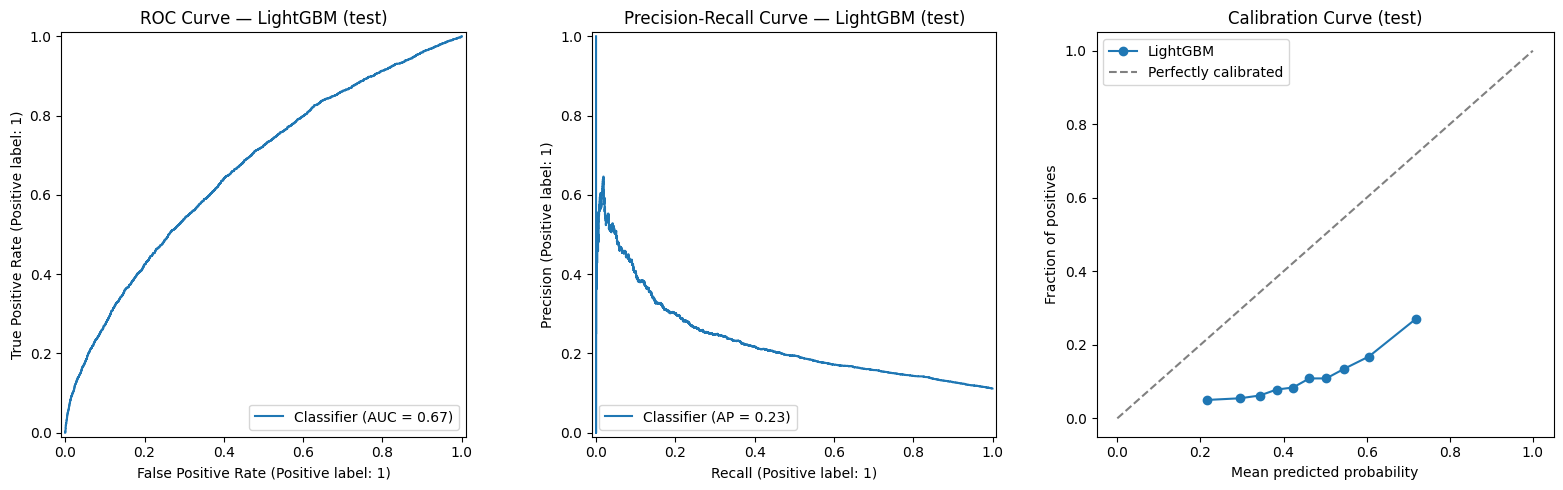

In [ ]:
# ROC curve, Precision-Recall curve, and calibration curve on the test set
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[0])
axes[0].set_title(f"ROC Curve — {best_model_name} (test)")

PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[1])
axes[1].set_title(f"Precision-Recall Curve — {best_model_name} (test)")

frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, marker="o", label=best_model_name)
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
axes[2].set_xlabel("Mean predicted probability")
axes[2].set_ylabel("Fraction of positives")
axes[2].set_title("Calibration Curve (test)")
axes[2].legend()

plt.tight_layout()
plt.show()

### 3.5 Summary

| Step | Decision |
|---|---|
| Models compared | Logistic Regression (baseline), Random Forest, Gradient Boosting (HistGB), XGBoost, LightGBM — **5 models** |
| CV scheme | `StratifiedGroupKFold`, 5 folds, patient-grouped + class-stratified |
| Primary selection metric | AUPRC (average precision), with Recall/F1/ROC-AUC reported alongside |
| Imbalance handling | Class weights / `scale_pos_weight` / `is_unbalance` — no resampling, no leakage risk |
| Preprocessing | Fit only inside training folds / on the training partition — never on test data |
| Threshold selection | Max-F2 on out-of-fold training predictions (test set untouched until final evaluation) |
| Final evaluation | Reported once on `X_test_model` / `y_test`, at both default and tuned thresholds |


## 4. Model Evaluation

**Owner:** Danah — Model Evaluation (Performance Metrics, Results Analysis, Confusion Matrix, ROC-AUC & Reports)

This section evaluates and interprets the final results generated in Section 3. The analysis focuses on AUPRC, ROC-AUC, Recall, Precision, and F1-score because 30-day readmission is an imbalanced classification problem. No models are retrained in this section.



### 4.1 Performance Metrics

The five candidate models were compared using 5-fold StratifiedGroupKFold cross-validation. AUPRC was used as the primary selection metric.

| Model                 |    ROC-AUC |      AUPRC | Recall |  Precision |     F1 |
| --------------------- | ---------: | ---------: | -----: | ---------: | -----: |
| **LightGBM**          |     0.6637 | **0.2214** | 0.5358 |     0.1852 | 0.2752 |
| GradientBoosting_Hist | **0.6663** |     0.2205 | 0.5780 |     0.1791 | 0.2733 |
| XGBoost               |     0.6618 |     0.2198 | 0.5353 |     0.1835 | 0.2732 |
| Logistic Regression   |     0.6614 |     0.2134 | 0.5355 |     0.1820 | 0.2716 |
| Random Forest         |     0.6649 |     0.2097 | 0.4293 | **0.2032** | 0.2757 |

After hyperparameter tuning, **LightGBM achieved the highest CV AUPRC (0.2239)** and was therefore selected as the final model.

On the held-out test set, the final LightGBM model achieved:

| Metric  | Test Result |
| ------- | ----------: |
| ROC-AUC |  **0.6677** |
| AUPRC   |  **0.2297** |

These results indicate moderate discrimination and an improvement over a random baseline for the minority class.

### 4.2 Confusion Matrix Analysis

The final model was evaluated at the default threshold of 0.5 and the optimized threshold of **0.4074**, selected using the maximum F2-score on out-of-fold training predictions.

| Threshold          | Precision |    Recall |        F1 |        TP |      FN |        FP |        TN |
| ------------------ | --------: | --------: | --------: | --------: | ------: | --------: | --------: |
| Default (0.5)      |     0.178 |     0.567 |     0.271 |     1,256 |     960 |     5,810 |    11,776 |
| **Tuned (0.4074)** | **0.147** | **0.773** | **0.247** | **1,713** | **503** | **9,956** | **7,630** |

At the tuned threshold:

* **TP = 1,713:** readmitted patients correctly identified by the model.
* **FN = 503:** readmitted patients missed by the model.
* **FP = 9,956:** non-readmitted patients incorrectly flagged as high-risk.
* **TN = 7,630:** non-readmitted patients correctly classified.

Lowering the threshold substantially increased recall from **56.7% to 77.3%**, reducing missed readmissions from 960 to 503. However, precision decreased from **17.8% to 14.7%**, resulting in a larger number of false-positive alerts.

### 4.3 ROC-AUC & Classification Performance

The final LightGBM model achieved a **ROC-AUC of 0.6677** and an **AUPRC of 0.2297** on the held-out test set.

The tuned threshold prioritizes recall over precision:

* **Recall = 0.773**
* **Precision = 0.147**
* **F1-score = 0.247**

The ROC-AUC indicates that the model discriminates between patients with and without 30-day readmission better than random classification. The AUPRC is also above the test-set positive-class rate of approximately **11.2%**, indicating useful minority-class prediction despite the class imbalance.

The ROC, Precision-Recall, and calibration curves generated in Section 3 provide additional visual support for these results.

### 4.4 Results Analysis

LightGBM achieved the highest cross-validated AUPRC after tuning, although the difference from XGBoost and HistGradientBoosting was small.

On the held-out test set, the model achieved ROC-AUC = 0.6677 and AUPRC = 0.2297, indicating moderate predictive performance.

Lowering the threshold from 0.5 to 0.4074 increased recall from 56.7% to 77.3%, while precision decreased from 17.8% to 14.7%. This shows the trade-off between detecting more readmitted patients and generating more false positives.

Overall, the model is better suited for risk screening and patient prioritization rather than standalone clinical decision-making.

### 4.5 Conclusion

Overall, the five candidate models showed relatively similar performance, with **LightGBM achieving the highest cross-validated AUPRC (0.2239)** after tuning. On the held-out test set, it achieved **ROC-AUC = 0.6677** and **AUPRC = 0.2297**.

Using the optimized threshold of **0.4074** increased recall to **77.3%** and reduced false negatives to **503**, but also lowered precision to **14.7%** and increased false positives.

The results suggest that the model has potential for **early risk screening and prioritizing patients for follow-up**, while its moderate discrimination and high false-positive burden should be considered limitations for practical deployment.